# 03 — Modelado de elasticidad

**Proyecto:** Análisis de Elasticidad de Demanda en Delivery de Comida (v2)
**Fase:** 3 — Modelado de elasticidad

Objetivos de este notebook:
1. Ajustar el modelo base log-log (elasticidad precio simple)
2. Ajustar un modelo log-log con variables de control (promoción, homepage, aumento de precio, efectos fijos por categoría y tipo de centro)
3. Ajustar una especificación alternativa semi-log, para comparación
4. Comparar las tres especificaciones con AIC/BIC y seleccionar la más adecuada
5. Calcular un intervalo de confianza por bootstrap para la elasticidad estimada


In [1]:
import sys
sys.path.append('../src')

import pandas as pd
from modeling import (
    modelo_log_log_base,
    modelo_log_log_controles,
    modelo_semilog,
    tabla_comparacion_modelos,
    bootstrap_elasticidad,
)

pd.set_option('display.max_columns', None)

In [2]:
from pathlib import Path

from IPython.display import display

REPORTS_DIR = Path('../reports')
NOTEBOOK_OUTPUTS_DIR = REPORTS_DIR / 'notebook_outputs'
NOTEBOOK_OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)


def guardar_texto(nombre_archivo: str, contenido: str) -> Path:
    ruta = NOTEBOOK_OUTPUTS_DIR / nombre_archivo
    ruta.write_text(str(contenido), encoding='utf-8')
    return ruta


def guardar_summary(nombre_archivo: str, resultado_modelo) -> tuple[Path, str]:
    texto = resultado_modelo.summary().as_text()
    ruta = guardar_texto(nombre_archivo, texto)
    return ruta, texto


def guardar_tabla(nombre_base: str, tabla: pd.DataFrame) -> tuple[Path, Path]:
    ruta_txt = NOTEBOOK_OUTPUTS_DIR / f'{nombre_base}.txt'
    ruta_csv = NOTEBOOK_OUTPUTS_DIR / f'{nombre_base}.csv'
    tabla.to_csv(ruta_csv, index=False)
    ruta_txt.write_text(tabla.to_string(index=False), encoding='utf-8')
    return ruta_txt, ruta_csv

## 1. Cargar el dataset procesado (Fase 2)

In [3]:
df = pd.read_csv('../data/processed/demanda_limpia.csv')
ruta_shape = guardar_texto('03_modelado_elasticidad_df_shape.txt', f'Shape del dataset: {df.shape}')
print(f'Shape del dataset: {df.shape}')
print(f'Guardado en {ruta_shape}')

Shape del dataset: (456548, 20)
Guardado en ../reports/notebook_outputs/03_modelado_elasticidad_df_shape.txt


## 2. Modelo base: log-log simple

`log_num_orders ~ log_checkout_price`

El coeficiente de `log_checkout_price` se interpreta directamente como la
elasticidad precio de la demanda: el cambio porcentual esperado en el número
de pedidos ante un cambio de 1% en el precio.

In [4]:
modelo_base = modelo_log_log_base(df)
ruta_resumen_base, resumen_base = guardar_summary('03_modelado_elasticidad_modelo_base_summary.txt', modelo_base)
print(resumen_base)
print(f'Summary guardado en {ruta_resumen_base}')

                            OLS Regression Results                            
Dep. Variable:         log_num_orders   R-squared:                       0.142
Model:                            OLS   Adj. R-squared:                  0.142
Method:                 Least Squares   F-statistic:                 7.561e+04
Date:                Thu, 22 Oct 2026   Prob (F-statistic):               0.00
Time:                        02:21:56   Log-Likelihood:            -7.0328e+05
No. Observations:              456548   AIC:                         1.407e+06
Df Residuals:                  456546   BIC:                         1.407e+06
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             10.2926      0

**Lectura del resultado:** el coeficiente de `log_checkout_price` (fila
correspondiente en la tabla de arriba) es la elasticidad estimada. Un
coeficiente de, por ejemplo, -1.2 significaría que un aumento de 1% en el
precio se asocia con una caída de 1.2% en el número de pedidos (demanda
elástica). Documentar el valor exacto obtenido, su error estándar y su
significancia (columna P>|t|) en la bitácora una vez corrida esta celda.

## 3. Modelo con variables de control

Se agregan: `emailer_for_promotion`, `homepage_featured`, `hubo_aumento`
(hallazgo de la Fase 2), y efectos fijos por categoría de comida
(`C(category)`) y tipo de centro (`C(center_type)`).

**Por qué agregar efectos fijos:** distintas categorías de comida y tipos de
centro pueden tener niveles de demanda base muy distintos, independientes del
precio. Sin controlar por esto, el coeficiente de precio podría capturar
parte de esas diferencias en vez de un efecto de precio puro.

In [5]:
modelo_controles = modelo_log_log_controles(df)
ruta_resumen_controles, resumen_controles = guardar_summary('03_modelado_elasticidad_modelo_controles_summary.txt', modelo_controles)
print(resumen_controles)
print(f'Summary guardado en {ruta_resumen_controles}')

                            OLS Regression Results                            
Dep. Variable:         log_num_orders   R-squared:                       0.531
Model:                            OLS   Adj. R-squared:                  0.531
Method:                 Least Squares   F-statistic:                 2.717e+04
Date:                Thu, 22 Oct 2026   Prob (F-statistic):               0.00
Time:                        02:21:59   Log-Likelihood:            -5.6559e+05
No. Observations:              456548   AIC:                         1.131e+06
Df Residuals:                  456528   BIC:                         1.131e+06
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

**Comparar con el modelo base:** ¿el coeficiente de `log_checkout_price`
cambió mucho al agregar controles? Si cambia poco, es una señal de robustez
del resultado. Si cambia mucho, sugiere que el modelo base estaba
confundiendo el efecto de precio con diferencias entre categorías/centros.

## 4. Especificación alternativa: semi-log

`log_num_orders ~ checkout_price` (precio en nivel, no logarítmico), con los
mismos controles. Aquí el coeficiente de precio ya no es una elasticidad
directa, sino un efecto semi-elástico (cambio porcentual en la demanda ante
un aumento de 1 unidad monetaria en el precio).

In [6]:
modelo_semi = modelo_semilog(df)
ruta_resumen_semi, resumen_semi = guardar_summary('03_modelado_elasticidad_modelo_semilog_summary.txt', modelo_semi)
print(resumen_semi)
print(f'Summary guardado en {ruta_resumen_semi}')

                            OLS Regression Results                            
Dep. Variable:         log_num_orders   R-squared:                       0.537
Model:                            OLS   Adj. R-squared:                  0.537
Method:                 Least Squares   F-statistic:                 2.787e+04
Date:                Thu, 22 Oct 2026   Prob (F-statistic):               0.00
Time:                        02:22:02   Log-Likelihood:            -5.6249e+05
No. Observations:              456548   AIC:                         1.125e+06
Df Residuals:                  456528   BIC:                         1.125e+06
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

## 5. Comparación de especificaciones (AIC / BIC)

AIC y BIC penalizan la complejidad del modelo (número de parámetros) además
de premiar el ajuste. Un valor más bajo indica mejor balance entre ajuste y
parsimonia. Se usan para decidir cuál especificación se reporta como
resultado principal del proyecto.

In [7]:
modelos = {
    'log-log base': modelo_base,
    'log-log con controles': modelo_controles,
    'semi-log con controles': modelo_semi,
}

tabla_modelos = tabla_comparacion_modelos(modelos)
ruta_tabla_modelos, ruta_csv_modelos = guardar_tabla('03_modelado_elasticidad_comparacion_modelos', tabla_modelos)
print(f'Tabla guardada en {ruta_csv_modelos} y {ruta_tabla_modelos}')
tabla_modelos

Tabla guardada en ../reports/notebook_outputs/03_modelado_elasticidad_comparacion_modelos.csv y ../reports/notebook_outputs/03_modelado_elasticidad_comparacion_modelos.txt


,modelo,aic,bic,r2_ajustado,n_observaciones
0,semi-log con controles,1.125018e+06,1.125239e+06,0.536985,456548
1,log-log con controles,1.131222e+06,1.131443e+06,0.530651,456548
2,log-log base,1.406573e+06,1.406595e+06,0.142088,456548


**Criterio de selección:** se elige el modelo con menor AIC/BIC entre las
especificaciones comparables (el modelo base no es directamente comparable
por AIC/BIC contra los otros dos porque tiene un conjunto de variables
distinto — la comparación relevante es entre 'log-log con controles' y
'semi-log con controles'). Documentar en la bitácora cuál resultó preferida
y por qué margen.

## 6. Intervalo de confianza por bootstrap para la elasticidad (COMENTADO - EJECUTAR EN VM)

Se remuestrea el dataset con reemplazo 1,000 veces, se reajusta el modelo
base en cada remuestra, y se guarda el coeficiente de `log_checkout_price`
en cada iteración. El intervalo de confianza al 95% se construye con los
percentiles 2.5 y 97.5 de esa distribución de coeficientes.

**Por qué esto importa:** el modelo base ya entrega un error estándar y un
intervalo de confianza analítico (visibles en el `summary()` de la sección
2), pero ese intervalo depende de los supuestos clásicos de OLS (normalidad
de errores, homocedasticidad), que se van a poner a prueba recién en la
Fase 4. El bootstrap es una forma no paramétrica de estimar la incertidumbre,
que no depende de esos supuestos, y sirve como verificación cruzada del
intervalo analítico.

**NOTA IMPORTANTE - CELDA COMENTADA:** Esta computación (1000 iteraciones sobre 456,548 filas)
tarda varios minutos. SE HA MOVIDO AL SCRIPT DE VM: `scripts/vm_computaciones_pesadas.py`
Ese script se ejecuta en una VM con GPU 100% dedicado + 32GB RAM y produce:
`reports/notebook_outputs/bootstrap_quantile_results.npy` (para cuantiles) y
`reports/notebook_outputs/bootstrap_panel_fe_results.npy` (para panel FE clusterizado).

El resultado del bootstrap simple OLS (modelo base) se cargará desde ese archivo .npy
en el pipeline principal (`scripts/reproducir_resultados_etapa3.py`), NO se ejecuta aquí.

**Nota de tiempo de ejecución:** con ~450,000 filas y 1,000 iteraciones, esta
celda puede tardar varios minutos. Si el tiempo es una limitante, reducir
`n_iteraciones` a 200-300 como primera aproximación.

In [8]:
# CELDA COMENTADA - Bootstrap simple OLS movido a VM (scripts/vm_computaciones_pesadas.py)
# Ver sección 6 arriba: esta computación se ejecuta en VM aparte y los resultados
# se cargan desde reports/notebook_outputs/bootstrap_quantile_results.npy (para cuantiles)
# y bootstrap_panel_fe_results.npy (para panel FE) en el pipeline principal.
#
# Código original (para referencia):
# resultado_bootstrap = bootstrap_elasticidad(df, n_iteraciones=1000)
# texto_bootstrap = (
#     f"Elasticidad media (bootstrap): {resultado_bootstrap['elasticidad_media']:.4f}\n"
#     f"Desviación estándar         : {resultado_bootstrap['elasticidad_std']:.4f}\n"
#     f"IC 95%                      : [{resultado_bootstrap['ic_95_inferior']:.4f}, "
#     f"{resultado_bootstrap['ic_95_superior']:.4f}]"
# )
# ruta_bootstrap = guardar_texto('03_modelado_elasticidad_bootstrap.txt', texto_bootstrap)
# print(texto_bootstrap)
# print(f'Resultados guardados en {ruta_bootstrap}')

print("CELDA COMENTADA: bootstrap_elasticidad (1000 iter) se ejecuta en VM aparte.")
print("Ver: scripts/vm_computaciones_pesadas.py")
print("Resultados se cargarán desde reports/notebook_outputs/*.npy en pipeline principal.")

CELDA COMENTADA: bootstrap_elasticidad (1000 iter) se ejecuta en VM aparte.
Ver: scripts/vm_computaciones_pesadas.py
Resultados se cargarán desde reports/notebook_outputs/*.npy en pipeline principal.


## 7. Guardar resultados de la Fase 3

Se guarda la tabla comparativa de modelos, para poder referenciarla
directamente en el informe final sin tener que re-ejecutar el notebook.

In [9]:
ruta_comparacion = guardar_texto('03_modelado_elasticidad_comparacion_modelos_generacion.txt', 'Guardado en reports/comparacion_modelos.csv y reports/notebook_outputs/03_modelado_elasticidad_comparacion_modelos.txt')
tabla_modelos.to_csv('../reports/comparacion_modelos.csv', index=False)
print(f'Guardado en reports/comparacion_modelos.csv y {ruta_comparacion}')

Guardado en reports/comparacion_modelos.csv y ../reports/notebook_outputs/03_modelado_elasticidad_comparacion_modelos_generacion.txt


## 8. Especificación flexible: RCS canónica y contraste F anidado

Restricted Cubic Splines en `log_checkout_price` con 4 nudos explícitos en P5/P35/P65/P95
(`src/rcs_utils.py`, base `cr(..., constraints='center')`, 3 columnas + intercepto). La
linealidad se contrasta comparando modelos anidados (log-log con controles frente a RCS,
2 g.l.). Nota: con esta base `rcs_1` sola no es lineal, por lo que `rcs_2 = rcs_3 = 0` **no**
es una hipótesis de linealidad.

In [10]:
import numpy as np
import statsmodels.formula.api as smf
from rcs_utils import build_canonical_rcs_design, apply_rcs_design

CTRL = 'emailer_for_promotion + homepage_featured + hubo_aumento + C(category) + C(center_type)'
design_info, nudos = build_canonical_rcs_design(df['log_checkout_price'].to_numpy())
S = apply_rcs_design(design_info, df['log_checkout_price'].to_numpy())
df_rcs = df.copy()
for col in S.columns:
    df_rcs[col] = S[col].to_numpy()
modelo_rcs = smf.ols(f'log_num_orders ~ rcs_1 + rcs_2 + rcs_3 + {CTRL}', data=df_rcs).fit()

F = ((modelo_controles.ssr - modelo_rcs.ssr) / 2) / (modelo_rcs.ssr / modelo_rcs.df_resid)
print('Nudos (precio):', np.round(np.exp(nudos), 2))
print(f'Contraste F anidado log-log vs RCS: F = {F:.2f}, gl = (2, {int(modelo_rcs.df_resid)})')
print(f'RCS: R2 ajustado = {modelo_rcs.rsquared_adj:.5f}, AIC = {modelo_rcs.aic:.2f}')

Nudos (precio): [121.28 260.02 349.26 640.23]
Contraste F anidado log-log vs RCS: F = 3607.28, gl = (2, 456526)
RCS: R2 ajustado = 0.53795, AIC = 1124067.47


In [11]:
def elasticidad_rcs(precios):
    h = 1e-5
    lp = np.log(np.atleast_1d(precios))
    dB = (np.asarray(apply_rcs_design(design_info, lp + h)) - np.asarray(apply_rcs_design(design_info, lp - h))) / (2 * h)
    return dB @ modelo_rcs.params[['rcs_1', 'rcs_2', 'rcs_3']].to_numpy()

for etiqueta, p in [('P5', np.exp(nudos[0])), ('P50', df['checkout_price'].median()),
                    ('Media', df['checkout_price'].mean()), ('P95', np.exp(nudos[3]))]:
    print(f'{etiqueta:>5} (precio {p:7.2f}): elasticidad = {elasticidad_rcs(p)[0]:+.4f}')

precio_eval = np.linspace(np.exp(nudos[0]), np.exp(nudos[3]), 300)
elasticidades = elasticidad_rcs(precio_eval)
print(f'Mínimo en [P5, P95]: {elasticidades.min():.4f} en precio {precio_eval[elasticidades.argmin()]:.1f}')

   P5 (precio  121.28): elasticidad = +0.0377
  P50 (precio  296.82): elasticidad = -1.4429
Media (precio  332.24): elasticidad = -1.5118
  P95 (precio  640.23): elasticidad = -1.2479
Mínimo en [P5, P95]: -1.5125 en precio 329.6


                             modelo          aic          bic  r2_ajustado  n_observaciones
log-log RCS (4 nudos) con controles 1.124067e+06 1.124310e+06     0.537950           456548
             semi-log con controles 1.125018e+06 1.125239e+06     0.536985           456548
              log-log con controles 1.131222e+06 1.131443e+06     0.530651           456548
                       log-log base 1.406573e+06 1.406595e+06     0.142088           456548


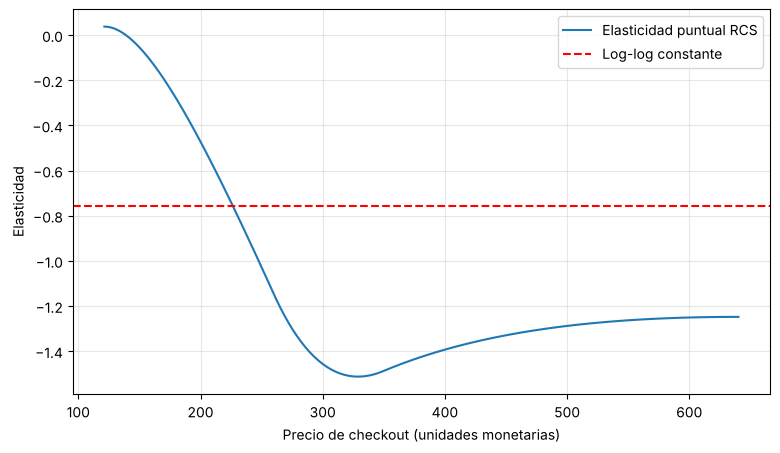

In [12]:
import matplotlib.pyplot as plt
modelos_todos = dict(modelos, **{'log-log RCS (4 nudos) con controles': modelo_rcs})
print(tabla_comparacion_modelos(modelos_todos).to_string(index=False))

plt.figure(figsize=(9, 5))
plt.plot(precio_eval, elasticidades, label='Elasticidad puntual RCS')
plt.axhline(modelo_controles.params['log_checkout_price'], color='r', ls='--', label='Log-log constante')
plt.xlabel('Precio de checkout (unidades monetarias)'); plt.ylabel('Elasticidad')
plt.legend(); plt.grid(alpha=.3); plt.show()

## Próximos pasos (Fase 4 — validación de supuestos)
- Test de heterocedasticidad (Breusch-Pagan) sobre el modelo seleccionado
- VIF para multicolinealidad entre las variables de control
- Normalidad de residuos (Q-Q plot)
- Discusión de limitaciones de identificación causal

In [13]:
# Estadísticos descriptivos - MOVIDO ANTES DE LA CELDA CONSOLIDADA
resumen_descriptivo = df[['checkout_price', 'base_price', 'num_orders', 'variacion_precio']].describe()
ruta_descriptivo = guardar_texto('03_modelado_elasticidad_descriptivo_variables.txt', resumen_descriptivo.to_string())
print(resumen_descriptivo)
print(f'Descriptivo guardado en {ruta_descriptivo}')

       checkout_price     base_price     num_orders  variacion_precio
count   456548.000000  456548.000000  456548.000000     456548.000000
mean       332.238933     354.156627     261.872760         21.917695
std        152.939723     160.715914     395.922798         48.495857
min          2.970000      55.350000      13.000000       -185.300000
25%        228.950000     243.500000      54.000000         -1.000000
50%        296.820000     310.460000     136.000000          1.000000
75%        445.230000     458.870000     324.000000         16.520000
max        866.270000     866.270000   24299.000000        561.600000
Descriptivo guardado en ../reports/notebook_outputs/03_modelado_elasticidad_descriptivo_variables.txt


In [14]:
# Equivalencia semi-log - MOVIDO ANTES DE LA CELDA CONSOLIDADA
precio_promedio = df['checkout_price'].mean()
elasticidad_semilog_equivalente = modelo_semi.params['checkout_price'] * precio_promedio
texto_equivalencia = (
    f'Precio promedio: {precio_promedio:.2f}\n'
    f'Elasticidad equivalente (semi-log, evaluada en la media): {elasticidad_semilog_equivalente:.4f}'
)
ruta_equivalencia = guardar_texto('03_modelado_elasticidad_equivalencia_semilog.txt', texto_equivalencia)
print(texto_equivalencia)
print(f'Guardado en {ruta_equivalencia}')

Precio promedio: 332.24
Elasticidad equivalente (semi-log, evaluada en la media): -1.0742
Guardado en ../reports/notebook_outputs/03_modelado_elasticidad_equivalencia_semilog.txt
